# Conciliación de unidades de calidad de cartera SFC

## Resumen
Conciliación aritmética entre razón y porcentaje reportados dentro del mismo extracto público.

## Contexto y método
Ambas columnas proceden del mismo extracto: esto verifica conversión de unidades, no concilia sistemas independientes ni saldos de cartera.

## Datos y preparación
Ejecutar desde la raíz del repositorio o la carpeta del proyecto. Requiere Python, pandas, matplotlib y Jupyter.

Fuente: [calidad de cartera SFC](https://www.superfinanciera.gov.co/loader.php?idFile=1070109&lFuncion=descargar&lServicio=Tools2&lTipo=descargas), corte diciembre de 2023; transformación y manifiesto en `01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/`.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True})

In [2]:
p=root/'03-financial-risk/01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/results/sfc_icv_entity_modality_month.csv'
df=pd.read_csv(p,parse_dates=['period']); df['diferencia_pp']=df.icv_reported_pct-100*df.icv_reported_ratio
print('SHA-256:',hashlib.sha256(p.read_bytes()).hexdigest())
print('Filas con ambas medidas:',df.diferencia_pp.notna().sum())
print('Máxima diferencia absoluta (puntos porcentuales):',df.diferencia_pp.abs().max())
df.groupby('modality').diferencia_pp.agg(['count','mean','max','min']).round(8)

SHA-256: 333144bae0eeae4713137a65a7126e7f39e2fe0bcf89337b366dda464e0c2fa8
Filas con ambas medidas: 21050
Máxima diferencia absoluta (puntos porcentuales): 5.00000002290335e-07


,count,mean,max,min
modality,,,,
Comercial,6459,0.000000e+00,5.000000e-07,-5.000000e-07
Consumo,6839,0.000000e+00,5.000000e-07,-5.000000e-07
Microcrédito,3597,0.000000e+00,5.000000e-07,-5.000000e-07
Vivienda,4155,1.000000e-08,5.000000e-07,-5.000000e-07


## Resultados

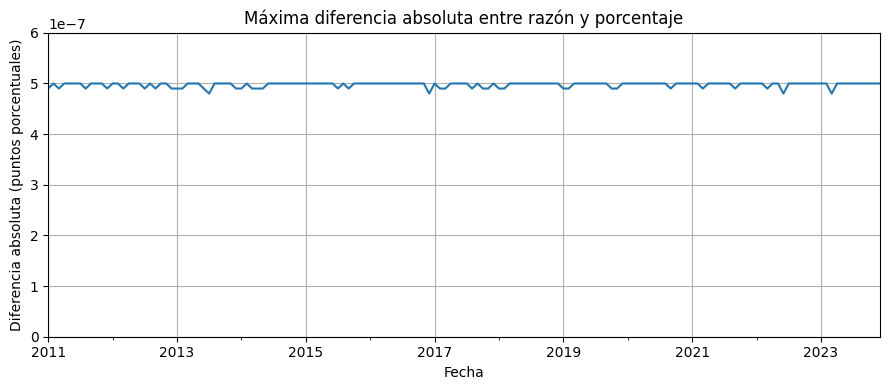

In [3]:
ax=df.groupby('period').diferencia_pp.apply(lambda x:x.abs().max()).plot(title='Máxima diferencia absoluta entre razón y porcentaje');ax.set(xlabel='Fecha',ylabel='Diferencia absoluta (puntos porcentuales)',ylim=(0,6e-7));plt.tight_layout();plt.show()

### Tolerancia de conciliación
La tolerancia es 0,000001 puntos porcentuales y se usa para detectar discrepancias de conversión, teniendo en cuenta el redondeo del extracto. Las dos columnas comparten origen y no constituyen conciliación entre sistemas independientes.

In [4]:
tolerancia_pp=1e-6
validas=df.diferencia_pp.notna()
desviaciones=df.loc[validas & (df.diferencia_pp.abs()>tolerancia_pp)]
print('Filas evaluadas:',int(validas.sum()),'| faltantes:',int((~validas).sum()))
print('Fuera de tolerancia:',len(desviaciones),'| tolerancia (puntos porcentuales):',tolerancia_pp)
assert not df.duplicated(['period','modality','entity_type_code','entity_code']).any()
desviaciones[['period','modality','entity_name','diferencia_pp']].head(10)

Filas evaluadas: 21050 | faltantes: 0
Fuera de tolerancia: 0 | tolerancia (puntos porcentuales): 1e-06


,period,modality,entity_name,diferencia_pp


## Variante: sensibilidad a la tolerancia
Para 0,0000001; 0,0000005 y 0,000001 puntos porcentuales se calcula la fracción de filas que excede cada tolerancia. La fracción es descriptiva del extracto, no una probabilidad de error poblacional. La aritmética de punto flotante puede afectar comparaciones exactamente en el umbral; no se infiere conciliación de sistemas. [Basilea SRP36](https://www.bis.org/committees/bcbs/basel-framework/standard/srp/36/inforce/2019-12-15/published/2019-12-15) fundamenta la necesidad de exactitud e integridad de la información de riesgo.

In [5]:
resultado=[]
for tol in [1e-7,5e-7,1e-6]:
    excede=df.loc[validas,'diferencia_pp'].abs()>tol
    resultado.append({'tolerancia_pp':tol,'filas_evaluadas':int(validas.sum()),'filas_superiores':int(excede.sum()),'fraccion_superior':float(excede.mean())})
pd.DataFrame(resultado)

,tolerancia_pp,filas_evaluadas,filas_superiores,fraccion_superior
0,1.000000e-07,21050,15551,0.738765
1,5.000000e-07,21050,123,0.005843
2,1.000000e-06,21050,0,0.000000


## Alcance y decisión
Ambas columnas proceden del mismo extracto: esto verifica conversión de unidades, no concilia sistemas independientes ni saldos de cartera.

Fuente y metodología detalladas en el README y en el companion de origen. Este ejercicio no constituye validación independiente.